# 04. Avaliação Retrospectiva (Fev-Ago/2026): Treino, Teste, Modelo Híbrido e Margens
**Artefato Analítico-Preditivo para Planejamento de Demanda e Mitigação de Desperdício**  
*Mestrado Profissional em Educação Profissional e Tecnológica (ProfEPT) / Gestão Pública*  
**Pesquisador:** Michel Silva de Souza  

---

## Storytelling: O Confronto de Inteligência e a Taxonomia de Ensembles
Com atributos construídos a partir da sexta de corte, submetemos os dados a um **torneio de Machine Learning** avaliado em validação *walk-forward* de fevereiro a agosto de 2026. Cada semana é prevista por um modelo treinado com os 12 meses anteriores à sexta de emissão.

### Os Dois Horizontes Decisórios Reais:
1. **$T+1$ (Preparo da Semana Seguinte - 3 a 7 dias de antecedência):** A decisão operacional que pode incorporar os cardápios publicados e a estimativa técnica da nutricionista.
2. **$T+2$ (Compras Quinzenais de Suprimentos - 10 a 14 dias de antecedência):** Decisão estritamente autônoma, na qual não há reservas discentes nem estimativas humanas disponíveis.

### A Taxonomia Completa de Ensembles Testada:
* **Bagging (Bootstrap Aggregating):** Random Forest e ExtraTrees (árvores paralelas com amostragem bootstrap independente para redução máxima de variância).
* **Boosting:** Gradient Boosting, AdaBoost, LightGBM, XGBoost e CatBoost (aprendizado sequencial nos resíduos ponderados).
* **Voting (Votação):** Média ponderada de estimadores heterogêneos (Ridge + ExtraTrees + CatBoost).
* **Stacking (Stacked Generalization):** Meta-aprendizado combinando modelos heterogêneos de primeiro nível através de um meta-regressor regularizado.
* **Blending:** Divisão temporal com holdout recente sem vazamento e cálculo de pesos não-negativos via NNLS.
* **Cascading (Cascata):** Modelo em dois estágios (estágio 1: âncora de tendência global; estágio 2: modelagem dos resíduos não-lineares).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from src.core.config import RESULTADOS
from src.core.models import PASTA_MODELOS

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 130


### 1. Carregamento dos Resultados de Fev-Ago/2026
Métricas de todos os modelos, cenários e horizontes em todos os dias com consumo do período (123 dias).


In [2]:
df_torneio = pd.read_csv(PASTA_MODELOS / "metricas_torneio_modelos.csv", sep=";", encoding="utf-8-sig")
df_metricas = pd.read_csv(RESULTADOS / "tabelas_dissertacao" / "tabela_03_desempenho_cenarios_retrospectivo.csv", sep=";", encoding="utf-8-sig")
df_metricas = df_metricas.merge(df_torneio[["algoritmo", "tipo_ensemble"]].drop_duplicates("algoritmo"), on="algoritmo", how="left")
df_metricas = df_metricas.rename(columns={"Sobra_Total_ref": "Total_Sobra_ref", "Deficit_Total_ref": "Total_Deficit_ref", "Taxa_Deficit_pct": "Taxa_Dias_Deficit_pct"})
print(f"Total de configurações avaliadas: {len(df_metricas)}")
df_metricas.head(10)


Total de configurações avaliadas: 154


,horizonte,cenario,algoritmo,n_dias,MAE,RMSE,R2,WAPE_pct,Total_Sobra_ref,Total_Deficit_ref,Dias_com_Deficit,Taxa_Dias_Deficit_pct,Dias_com_Sobra,Taxa_Sobra_pct,Saldo_Operacional_ref,Custo_Potencial_Sobras_RS,tipo_ensemble
0,t1,Cenario_1_Base_Cardapio,Arvore_Decisao,123,43.15,69.35,-0.959,25.80,3693,1614,60 (48.8%),48.8,61 (49.6%),49.6,2079,51702.0,Nenhum (Árvore Única)
1,t1,Cenario_1_Base_Cardapio,Baseline_Mesmo_Dia_Semana,123,30.95,46.71,0.111,18.51,2133,1674,68 (55.3%),55.3,53 (43.1%),43.1,459,29862.0,Nenhum (Heurística Estática)
2,t1,Cenario_1_Base_Cardapio,Baseline_Nivel_Recente_10d,123,41.46,52.93,-0.142,24.79,2783,2317,66 (53.7%),53.7,55 (44.7%),44.7,466,38962.0,Nenhum (Heurística Estática)
3,t1,Cenario_1_Base_Cardapio,ElasticNet,123,29.26,40.03,0.347,17.50,1474,2125,76 (61.8%),61.8,45 (36.6%),36.6,-651,20636.0,Nenhum (L1+L2 Regularized)
4,t1,Cenario_1_Base_Cardapio,Ensemble_Bagging_Arvores,123,31.74,48.14,0.056,18.98,2397,1507,65 (52.8%),52.8,57 (46.3%),46.3,890,33558.0,Bagging (Árvores de Decisão)
5,t1,Cenario_1_Base_Cardapio,Ensemble_Bagging_ExtraTrees,123,27.85,41.07,0.313,16.66,1769,1657,67 (54.5%),54.5,52 (42.3%),42.3,112,24766.0,Bagging (Árvores Extremamente Aleatórias)
6,t1,Cenario_1_Base_Cardapio,Ensemble_Bagging_RandomForest,123,30.06,44.64,0.188,17.97,2081,1616,66 (53.7%),53.7,56 (45.5%),45.5,465,29134.0,Bagging (Bootstrap Paralelo)
7,t1,Cenario_1_Base_Cardapio,Ensemble_Blending_Holdout,123,31.84,45.12,0.170,19.04,1635,2281,74 (60.2%),60.2,48 (39.0%),39.0,-646,22890.0,Blending (Holdout Temporal NNLS)
8,t1,Cenario_1_Base_Cardapio,Ensemble_Boosting_AdaBoost,123,30.99,45.09,0.172,18.53,2117,1695,70 (56.9%),56.9,53 (43.1%),43.1,422,29638.0,Boosting (AdaBoost Adaptativo)
9,t1,Cenario_1_Base_Cardapio,Ensemble_Boosting_CatBoost,123,29.46,41.61,0.295,17.62,1861,1763,69 (56.1%),56.1,53 (43.1%),43.1,98,26054.0,Boosting (CatBoost Simétrico)


## 2. Horizonte T+1 (Preparo Diário): O Impacto dos Cenários e dos Ensembles
No horizonte de curto prazo ($T+1$), avaliamos como o acréscimo de Cardápio, Clima e Nutricionista reduz o erro médio (MAE) e o WAPE.

In [3]:
t1_df = df_metricas[df_metricas["horizonte"] == "t1"].sort_values("MAE")
t1_top = t1_df[["cenario", "algoritmo", "tipo_ensemble", "MAE", "RMSE", "WAPE_pct", "Total_Sobra_ref", "Total_Deficit_ref", "Taxa_Dias_Deficit_pct"]].head(12)
t1_top


,cenario,algoritmo,tipo_ensemble,MAE,RMSE,WAPE_pct,Total_Sobra_ref,Total_Deficit_ref,Taxa_Dias_Deficit_pct
83,Cenario_4_Com_Nutricionista,Lasso,Nenhum (L1 Sparse),23.27,34.26,13.91,1584,1278,57.7
69,Cenario_4_Com_Nutricionista,ElasticNet,Nenhum (L1+L2 Regularized),23.30,33.71,13.93,1446,1420,62.6
86,Cenario_4_Com_Nutricionista,Ridge,Nenhum (L2 Regularized),24.25,33.51,14.50,1297,1686,65.0
81,Cenario_4_Com_Nutricionista,Ensemble_Voting_Heterogeneo,Voting (Votação Ponderada Heterogênea),24.35,35.77,14.56,1562,1433,57.7
71,Cenario_4_Com_Nutricionista,Ensemble_Bagging_ExtraTrees,Bagging (Árvores Extremamente Aleatórias),26.21,39.20,15.67,1768,1456,52.8
85,Cenario_4_Com_Nutricionista,Regressao_Linear,Nenhum (Modelo Base),26.24,36.54,15.69,1339,1888,65.9
77,Cenario_4_Com_Nutricionista,Ensemble_Boosting_LightGBM,Boosting (LightGBM Leaf-wise),26.54,39.23,15.87,1872,1393,52.8
76,Cenario_4_Com_Nutricionista,Ensemble_Boosting_Gradient,Boosting (Gradient Boosting Robusto),26.68,38.83,15.96,1838,1444,52.0
72,Cenario_4_Com_Nutricionista,Ensemble_Bagging_RandomForest,Bagging (Bootstrap Paralelo),26.76,39.52,16.00,1912,1380,50.4
78,Cenario_4_Com_Nutricionista,Ensemble_Boosting_XGBoost,Boosting (XGBoost Regularizado),26.91,39.62,16.09,1918,1392,53.7


### Visualização: Comparativo de MAE por Família de Ensemble em T+1

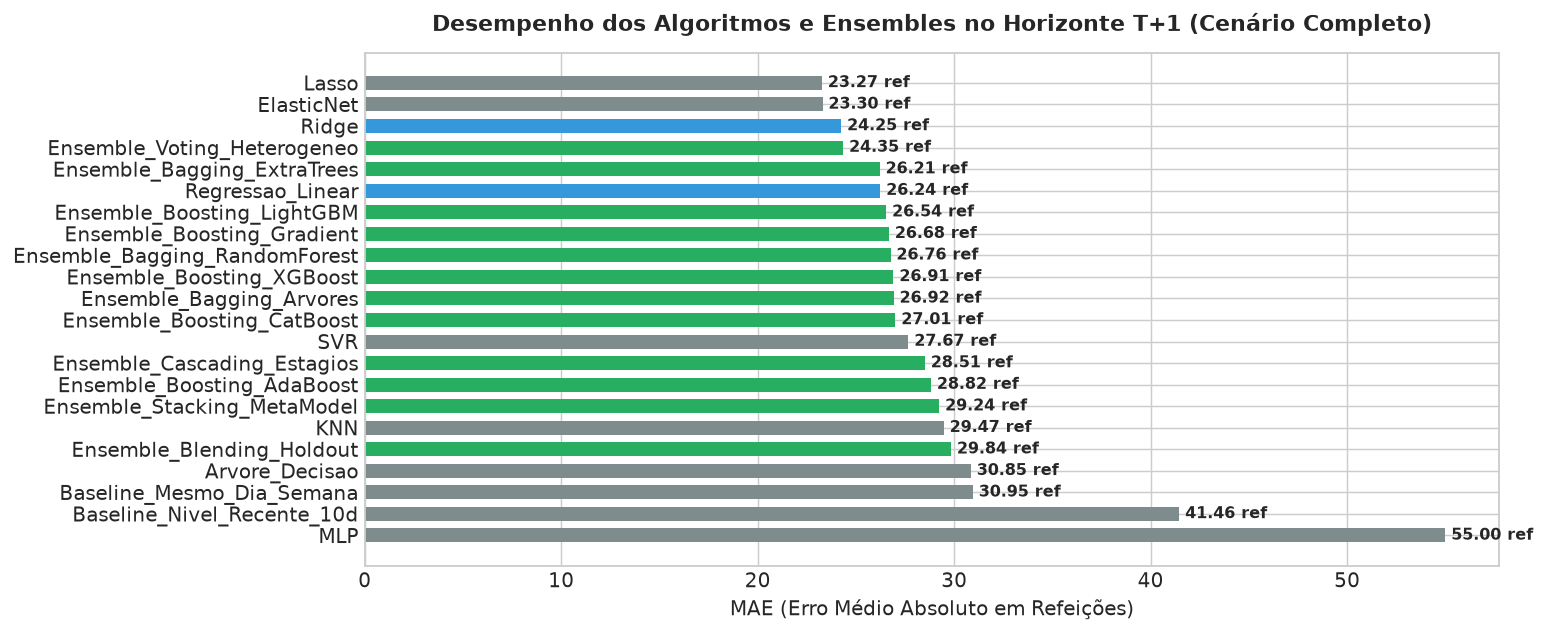

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))
c4_df = t1_df[t1_df["cenario"] == "Cenario_4_Com_Nutricionista"].sort_values("MAE", ascending=False)

cores = ["#27ae60" if "Ensemble" in a else "#3498db" if "Ridge" in a or "Linear" in a else "#7f8c8d" for a in c4_df["algoritmo"]]
ax.barh(c4_df["algoritmo"], c4_df["MAE"], color=cores, height=0.65)
ax.set_title("Desempenho dos Algoritmos e Ensembles no Horizonte T+1 (Cenário Completo)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("MAE (Erro Médio Absoluto em Refeições)")
for i, (mae, alg) in enumerate(zip(c4_df["MAE"], c4_df["algoritmo"])):
    ax.text(mae + 0.3, i, f"{mae:.2f} ref", va="center", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.show()


## 3. Horizonte T+2 (Compras Quinzenais): O Campeão Autônomo
Para a gestão de compras com 10 a 14 dias de antecedência, nenhum dado humano pode ser utilizado. Identificamos os modelos que alcançam o menor desperdício e erro médio de forma 100% independente.

In [5]:
t2_df = df_metricas[df_metricas["horizonte"] == "t2"].sort_values("MAE")
t2_top = t2_df[["cenario", "algoritmo", "tipo_ensemble", "MAE", "RMSE", "WAPE_pct", "Total_Sobra_ref", "Total_Deficit_ref", "Taxa_Dias_Deficit_pct"]].head(10)
t2_top


,cenario,algoritmo,tipo_ensemble,MAE,RMSE,WAPE_pct,Total_Sobra_ref,Total_Deficit_ref,Taxa_Dias_Deficit_pct
93,Cenario_1_Base_Cardapio,Ensemble_Bagging_ExtraTrees,Bagging (Árvores Extremamente Aleatórias),27.93,42.28,16.70,1708,1727,56.9
125,Cenario_2_Com_Cardapio,Ensemble_Voting_Heterogeneo,Voting (Votação Ponderada Heterogênea),28.02,41.35,16.76,1677,1770,61.8
115,Cenario_2_Com_Cardapio,Ensemble_Bagging_ExtraTrees,Bagging (Árvores Extremamente Aleatórias),28.18,43.05,16.85,1778,1688,55.3
137,Cenario_3_Com_Clima,Ensemble_Bagging_ExtraTrees,Bagging (Árvores Extremamente Aleatórias),28.47,42.91,17.02,1767,1735,58.5
127,Cenario_2_Com_Cardapio,Lasso,Nenhum (L1 Sparse),28.60,40.99,17.10,1745,1773,56.1
103,Cenario_1_Base_Cardapio,Ensemble_Voting_Heterogeneo,Voting (Votação Ponderada Heterogênea),28.75,42.29,17.19,1636,1900,62.6
147,Cenario_3_Com_Clima,Ensemble_Voting_Heterogeneo,Voting (Votação Ponderada Heterogênea),28.87,41.86,17.26,1620,1931,63.4
140,Cenario_3_Com_Clima,Ensemble_Boosting_AdaBoost,Boosting (AdaBoost Adaptativo),28.90,42.29,17.28,1864,1691,54.5
149,Cenario_3_Com_Clima,Lasso,Nenhum (L1 Sparse),28.96,41.29,17.32,1731,1831,58.5
118,Cenario_2_Com_Cardapio,Ensemble_Boosting_AdaBoost,Boosting (AdaBoost Adaptativo),28.96,42.12,17.32,1821,1741,56.9


### Visualização: Ranking Top 10 em Compras (T+2 Autônomo)

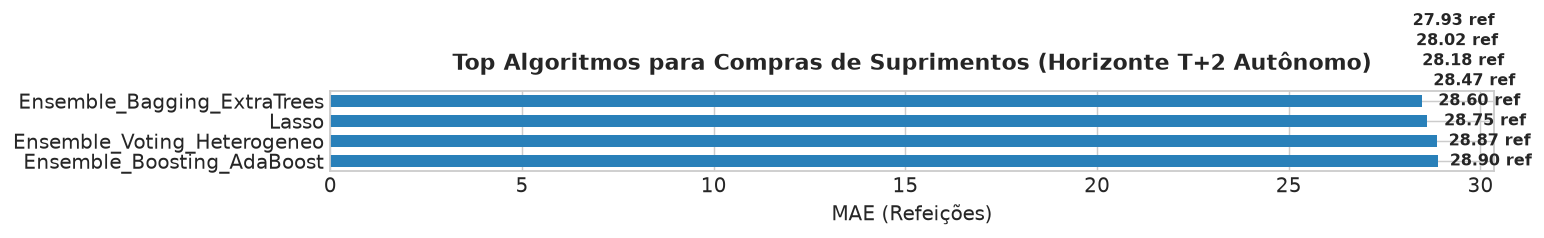

In [6]:
fig, ax = plt.subplots(figsize=(12, 4.5))
t2_top_plot = t2_top.head(8).sort_values("MAE", ascending=False)

ax.barh(t2_top_plot["algoritmo"], t2_top_plot["MAE"], color="#2980b9", height=0.6)
ax.set_title("Top Algoritmos para Compras de Suprimentos (Horizonte T+2 Autônomo)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("MAE (Refeições)")
for i, mae in enumerate(t2_top_plot["MAE"]):
    ax.text(mae + 0.3, i, f"{mae:.2f} ref", va="center", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.show()


## 4. Comparativo Sistemático das 6 Famílias de Ensemble
Resumo comparativo do comportamento de cada tipo de ensemble na modelagem preditiva da escola pública.

In [7]:
comp_familias = df_metricas.groupby(["tipo_ensemble"])[["MAE", "RMSE", "WAPE_pct"]].mean().sort_values("MAE").round(2)
comp_familias.columns = ["MAE Médio", "RMSE Médio", "WAPE Médio (%)"]
comp_familias


,MAE Médio,RMSE Médio,WAPE Médio (%)
tipo_ensemble,,,
Voting (Votação Ponderada Heterogênea),27.55,39.99,16.47
Nenhum (L1 Sparse),27.79,39.43,16.62
Bagging (Árvores Extremamente Aleatórias),27.81,41.59,16.63
Nenhum (L1+L2 Regularized),28.34,39.60,16.94
Nenhum (L2 Regularized),28.89,39.38,17.28
Boosting (XGBoost Regularizado),29.10,41.85,17.40
Boosting (Gradient Boosting Robusto),29.16,42.49,17.44
Bagging (Bootstrap Paralelo),29.25,43.63,17.49
Boosting (AdaBoost Adaptativo),29.75,43.23,17.79


## 5. Seleção do Melhor Modelo no Melhor Cenário
A regra usa apenas Fev-Ago/2026: em cada horizonte, vence a configuração de menor MAE, com o RMSE como desempate. No preparo ($T+1$) concorrem os modelos isolados de C1 a C4 e os híbridos 50/50 de C1 a C3. Nas compras ($T+2$) concorrem os modelos isolados de C1 a C3, pois não há quantitativo institucional.


In [8]:
import json
candidatos = pd.read_csv(PASTA_MODELOS / "selecao_candidatos_fev_ago.csv", sep=";", encoding="utf-8-sig")
for h in ("t1", "t2"):
    display(candidatos[candidatos["horizonte"] == h].head(8).round(2))
print(json.dumps(json.loads((PASTA_MODELOS / "selecao_modelos.json").read_text(encoding="utf-8"))["vencedores"], ensure_ascii=False, indent=1))


,horizonte,cenario,algoritmo,tipo,n_dias,MAE,RMSE,WAPE_pct,R2,Sobra,Deficit
0,t1,Cenario_2_Com_Cardapio,Ridge,hibrido,123,22.08,33.39,13.20,0.55,1723.0,993.0
1,t1,Cenario_3_Com_Clima,Ridge,hibrido,123,22.19,33.42,13.27,0.54,1730.0,999.0
2,t1,Cenario_3_Com_Clima,Lasso,hibrido,123,22.39,34.21,13.39,0.52,1821.0,933.0
3,t1,Cenario_2_Com_Cardapio,ElasticNet,hibrido,123,22.41,33.90,13.40,0.53,1783.0,973.0
4,t1,Cenario_2_Com_Cardapio,Lasso,hibrido,123,22.43,34.19,13.41,0.52,1816.0,943.0
5,t1,Cenario_1_Base_Cardapio,Lasso,hibrido,123,22.46,34.44,13.43,0.52,1776.0,987.0
6,t1,Cenario_3_Com_Clima,ElasticNet,hibrido,123,22.51,33.96,13.46,0.53,1786.0,983.0
7,t1,Cenario_1_Base_Cardapio,Ridge,hibrido,123,22.67,33.93,13.56,0.53,1649.0,1140.0


,horizonte,cenario,algoritmo,tipo,n_dias,MAE,RMSE,WAPE_pct,R2,Sobra,Deficit
140,t2,Cenario_1_Base_Cardapio,Ensemble_Bagging_ExtraTrees,isolado,123,27.93,42.28,16.70,0.27,1708.0,1727.0
141,t2,Cenario_2_Com_Cardapio,Ensemble_Voting_Heterogeneo,isolado,123,28.02,41.35,16.76,0.30,1677.0,1770.0
142,t2,Cenario_2_Com_Cardapio,Ensemble_Bagging_ExtraTrees,isolado,123,28.18,43.05,16.85,0.25,1778.0,1688.0
143,t2,Cenario_3_Com_Clima,Ensemble_Bagging_ExtraTrees,isolado,123,28.47,42.91,17.02,0.25,1767.0,1735.0
144,t2,Cenario_2_Com_Cardapio,Lasso,isolado,123,28.60,40.99,17.10,0.32,1745.0,1773.0
145,t2,Cenario_1_Base_Cardapio,Ensemble_Voting_Heterogeneo,isolado,123,28.75,42.29,17.19,0.27,1636.0,1900.0
146,t2,Cenario_3_Com_Clima,Ensemble_Voting_Heterogeneo,isolado,123,28.87,41.86,17.26,0.29,1620.0,1931.0
147,t2,Cenario_3_Com_Clima,Ensemble_Boosting_AdaBoost,isolado,123,28.90,42.29,17.28,0.27,1864.0,1691.0


{
 "t1": {
  "algoritmo": "Ridge",
  "cenario": "Cenario_2_Com_Cardapio",
  "tipo": "hibrido",
  "MAE": 22.08,
  "RMSE": 33.39,
  "n_dias": 123
 },
 "t2": {
  "algoritmo": "Ensemble_Bagging_ExtraTrees",
  "cenario": "Cenario_1_Base_Cardapio",
  "tipo": "isolado",
  "MAE": 27.93,
  "RMSE": 42.28,
  "n_dias": 123
 }
}


## 6. Modelo Híbrido e Margens de Segurança (Fev-Ago/2026)
### 6.1. Modelos vs. Nutricionista
Confronto dos modelos com a estimativa humana em $T+1$.


=== TABELA 04: MODELOS PREDITIVOS VS. NUTRICIONISTA (T+1 - FEV-AGO/2026) ===


,Modelo / Origem,Familia,Cenario,MAE,RMSE,WAPE_pct,Sobra_Total_ref,Deficit_Total_ref,Taxa_Deficit_pct,Custo_Potencial_Sobras_RS
0,Nutricionista Institucional (Humano),Especialista Humano,Referência Operacional,26.21,39.45,15.67,2561,663,39.0,35854.0
1,Lasso,Linear,Cenario_4_Com_Nutricionista,23.27,34.26,13.91,1584,1278,57.7,22176.0
2,ElasticNet,Linear,Cenario_4_Com_Nutricionista,23.30,33.71,13.93,1446,1420,62.6,20244.0
3,Ridge,Linear,Cenario_4_Com_Nutricionista,24.25,33.51,14.50,1297,1686,65.0,18158.0
4,Ensemble_Voting_Heterogeneo,Voting,Cenario_4_Com_Nutricionista,24.35,35.77,14.56,1562,1433,57.7,21868.0
5,Ensemble_Bagging_ExtraTrees,Bagging,Cenario_4_Com_Nutricionista,26.21,39.20,15.67,1768,1456,52.8,24752.0
6,Regressao_Linear,Linear,Cenario_4_Com_Nutricionista,26.24,36.54,15.69,1339,1888,65.9,18746.0
7,Ensemble_Voting_Heterogeneo,Voting,Cenario_2_Com_Cardapio,27.40,39.37,16.38,1671,1699,58.5,23394.0
8,Ridge,Linear,Cenario_2_Com_Cardapio,27.48,37.54,16.43,1437,1943,61.0,20118.0
9,Ensemble_Bagging_ExtraTrees,Bagging,Cenario_2_Com_Cardapio,27.79,41.07,16.62,1758,1660,56.1,24612.0


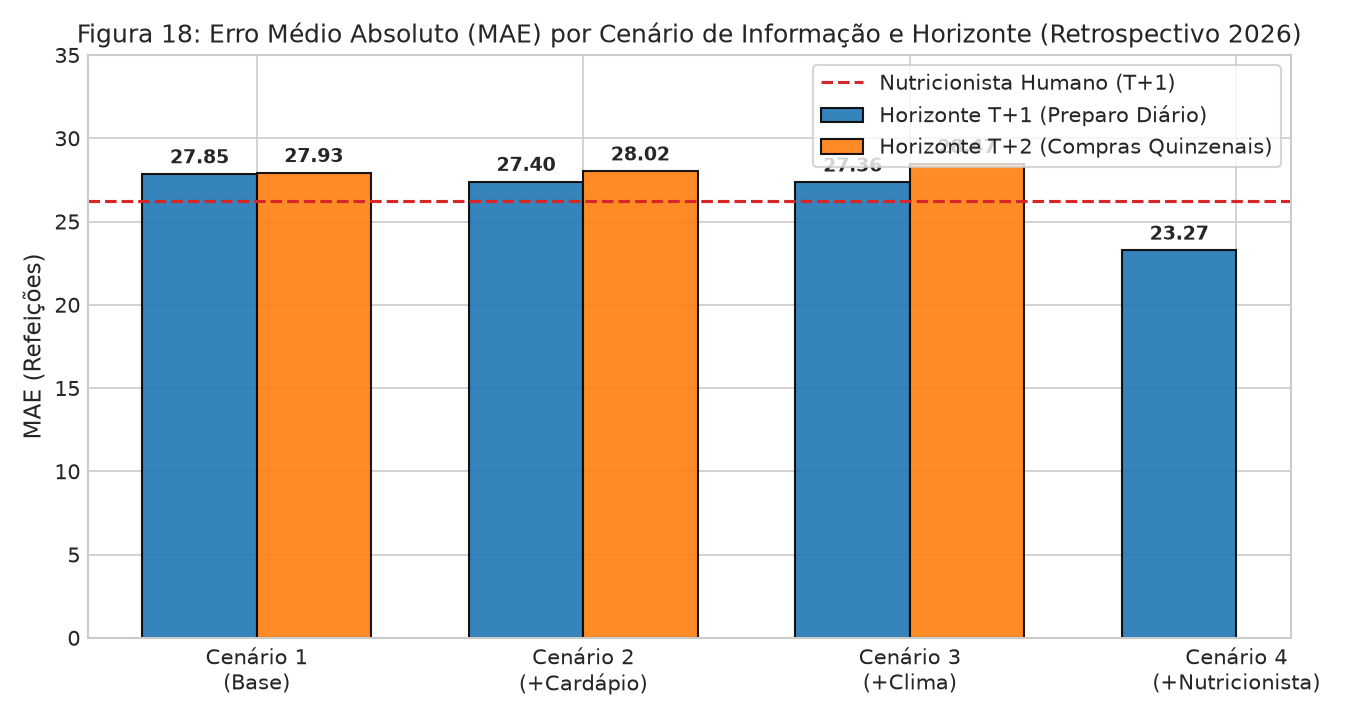

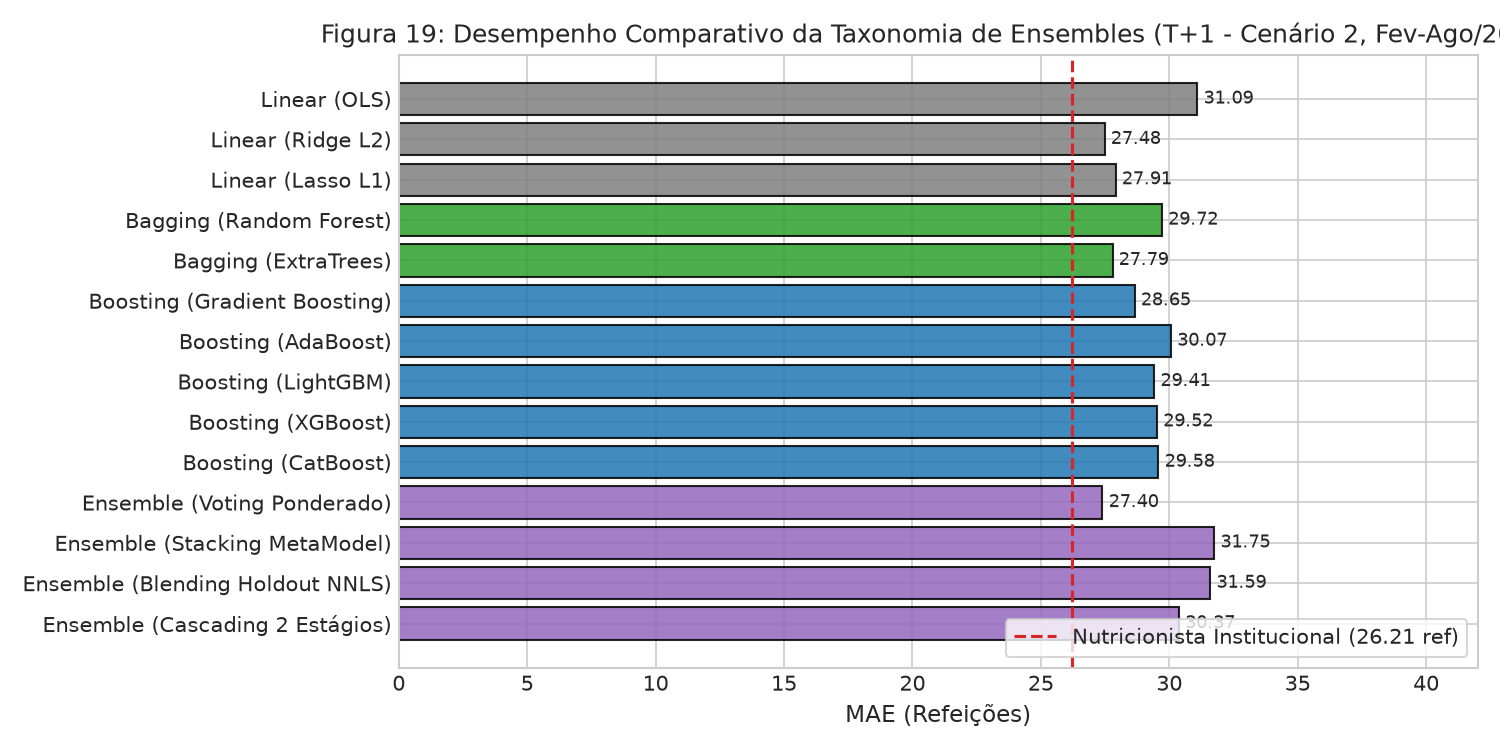

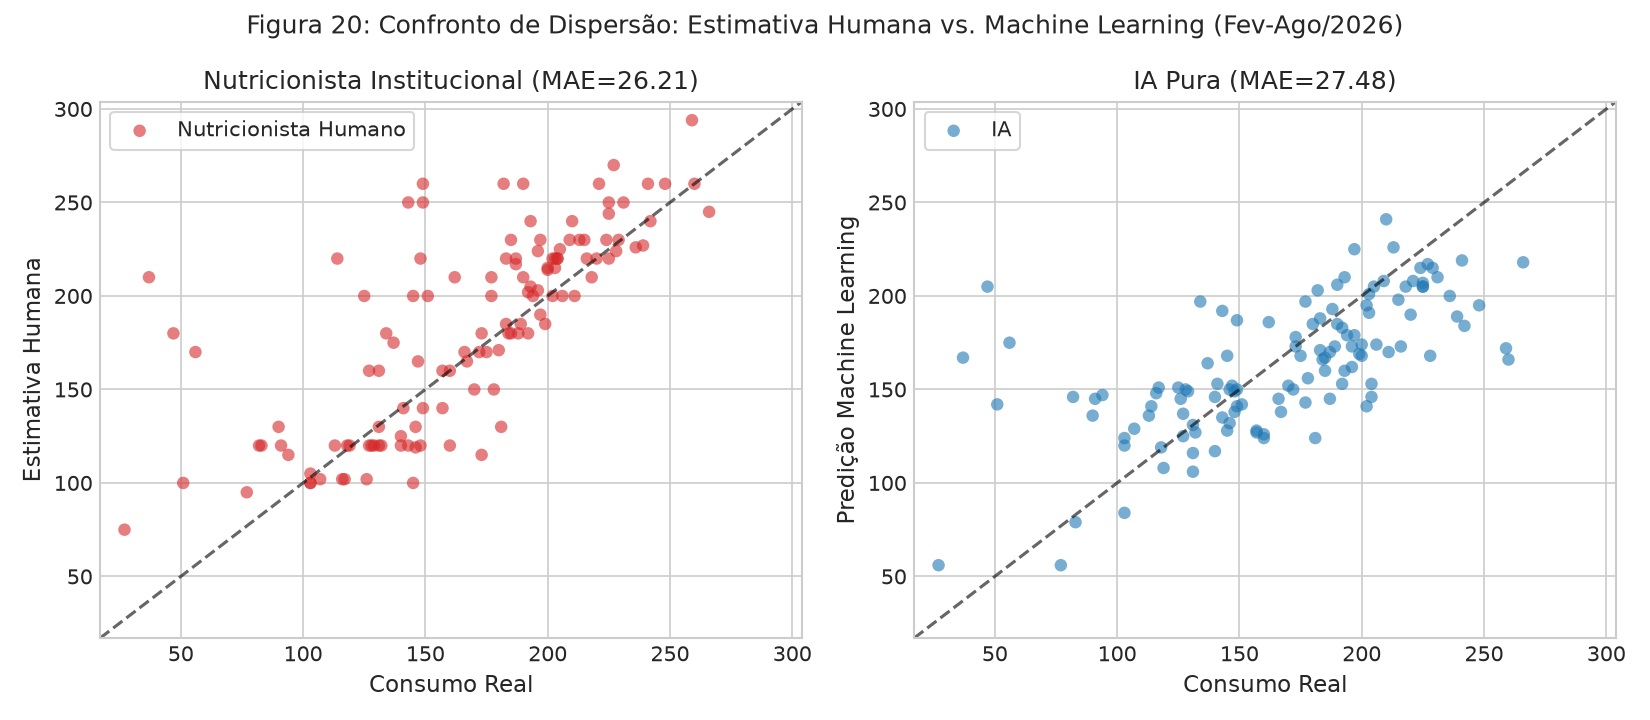

In [9]:
from IPython.display import Image, display
from src.core.safety_margins import PASTA_TABELAS, PASTA_FIGURAS

tabela_04 = pd.read_csv(PASTA_TABELAS / "tabela_04_modelos_vs_nutricionista_t1_retrospectivo.csv", sep=";")
print("=== TABELA 04: MODELOS PREDITIVOS VS. NUTRICIONISTA (T+1 - FEV-AGO/2026) ===")
display(tabela_04[["Modelo / Origem", "Familia", "Cenario", "MAE", "RMSE", "WAPE_pct", "Sobra_Total_ref", "Deficit_Total_ref", "Taxa_Deficit_pct", "Custo_Potencial_Sobras_RS"]].head(10))
display(Image(filename=str(PASTA_FIGURAS / "figura_18_ablation_cenarios_horizontes_retrospectivo.png")))
display(Image(filename=str(PASTA_FIGURAS / "figura_19_confronto_taxonomia_ensembles_retrospectivo.png")))
display(Image(filename=str(PASTA_FIGURAS / "figura_20_modelos_vs_nutricionista_t1_retrospectivo.png")))


### 6.2. O Modelo Híbrido ($T+1$)
Combinação linear convexa: $\hat{y}_{\text{híbrido}} = w \cdot \hat{y}_{\text{IA}} + (1 - w) \cdot \hat{y}_{\text{nutri}}$.


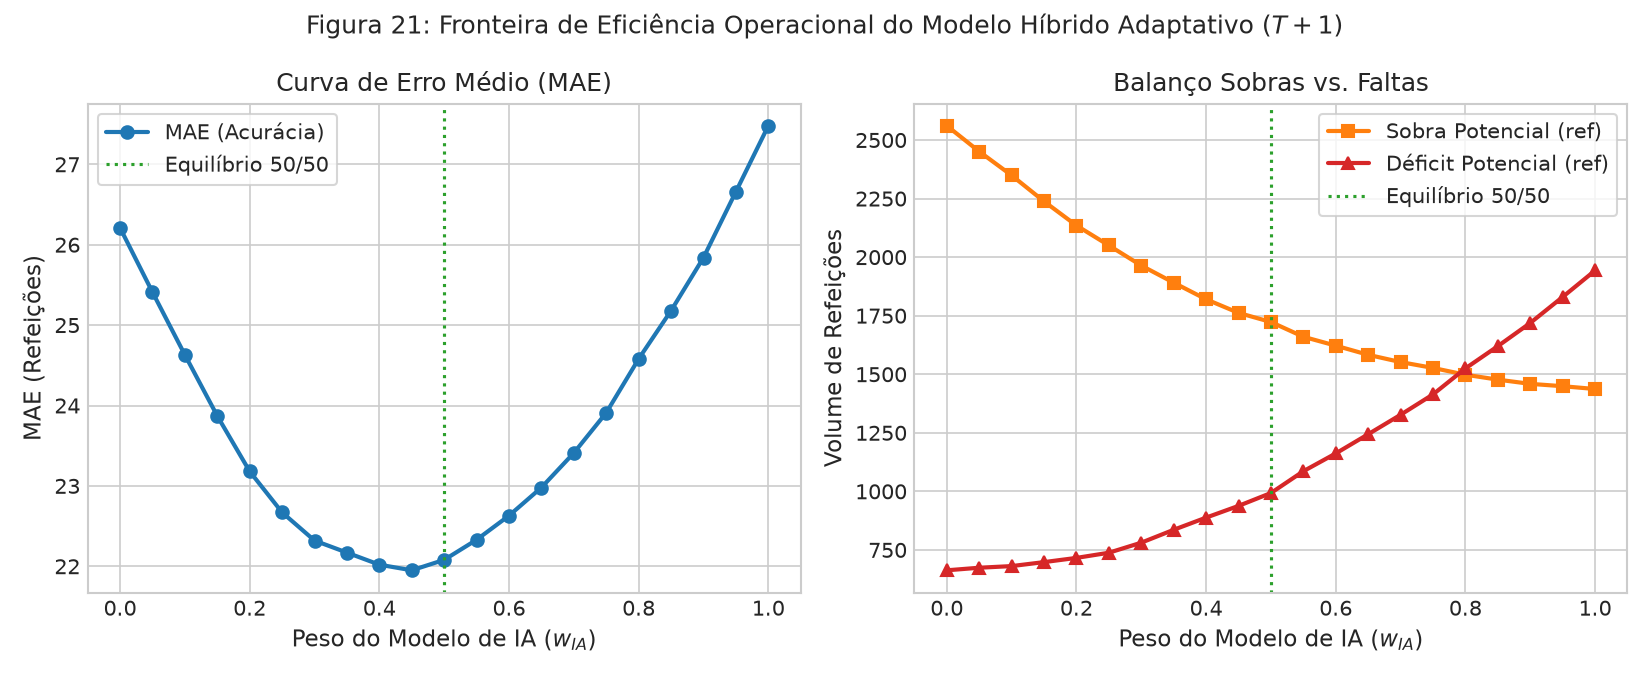

In [10]:
display(Image(filename=str(PASTA_FIGURAS / "figura_21_fronteira_equilibrio_modelo_hibrido_retrospectivo.png")))


### 6.3. Margens Empíricas por Quantil e Trade-off Operacional
As margens são os quantis P75, P85 e P90 da falta observada em Fev-Ago, calculados a partir dos resíduos e arredondados para cima.


=== TABELA 05: AVALIAÇÃO DE POLÍTICAS E MARGENS EMPÍRICAS (FEV-AGO/2026) ===


,Politica,Quantil,Margem,MAE,Sobra_Total_ref,Deficit_Total_ref,Dias_com_Deficit,Taxa_Deficit_pct,Custo_Potencial_Sobras_RS
0,Nutricionista Institucional,Sem margem,+0 ref,26.21,2561,663,48 (39.0%),39.0,35854.0
1,IA Pura,Sem margem,+0 ref,27.48,1437,1943,75 (61.0%),61.0,20118.0
2,IA Pura,P75,+24 ref,29.53,3039,593,31 (25.2%),25.2,42546.0
3,IA Pura,P85,+34 ref,35.35,4012,336,17 (13.8%),13.8,56168.0
4,IA Pura,P90,+42 ref,41.40,4876,216,12 (9.8%),9.8,68264.0
5,Modelo Híbrido 50/50,Sem margem,+0 ref,22.08,1723,993,65 (52.8%),52.8,24122.0
6,Modelo Híbrido 50/50,P75,+14 ref,25.54,2797,345,31 (25.2%),25.2,39158.0
7,Modelo Híbrido 50/50,P85,+21 ref,29.63,3479,166,17 (13.8%),13.8,48706.0
8,Modelo Híbrido 50/50,P90,+25 ref,32.64,3910,105,12 (9.8%),9.8,54740.0


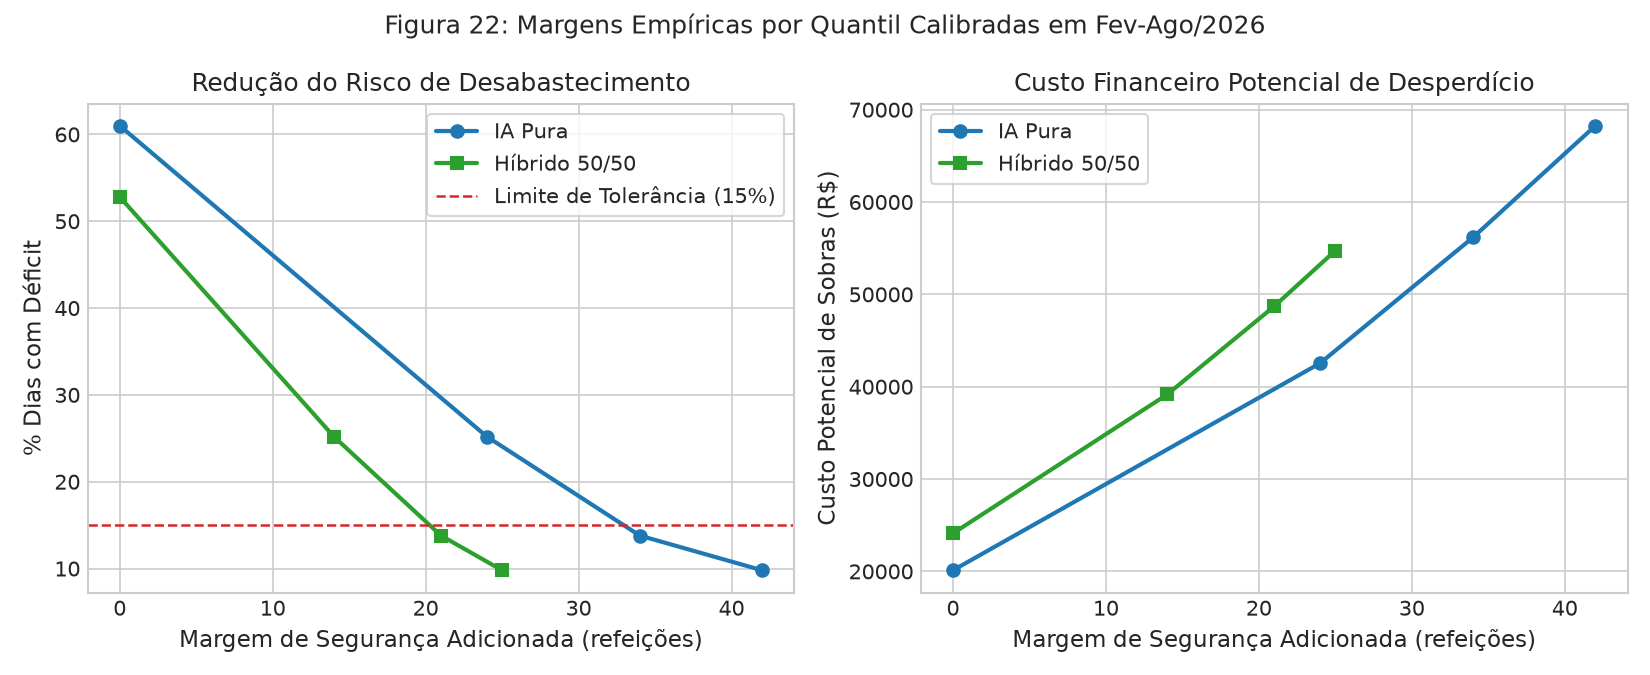

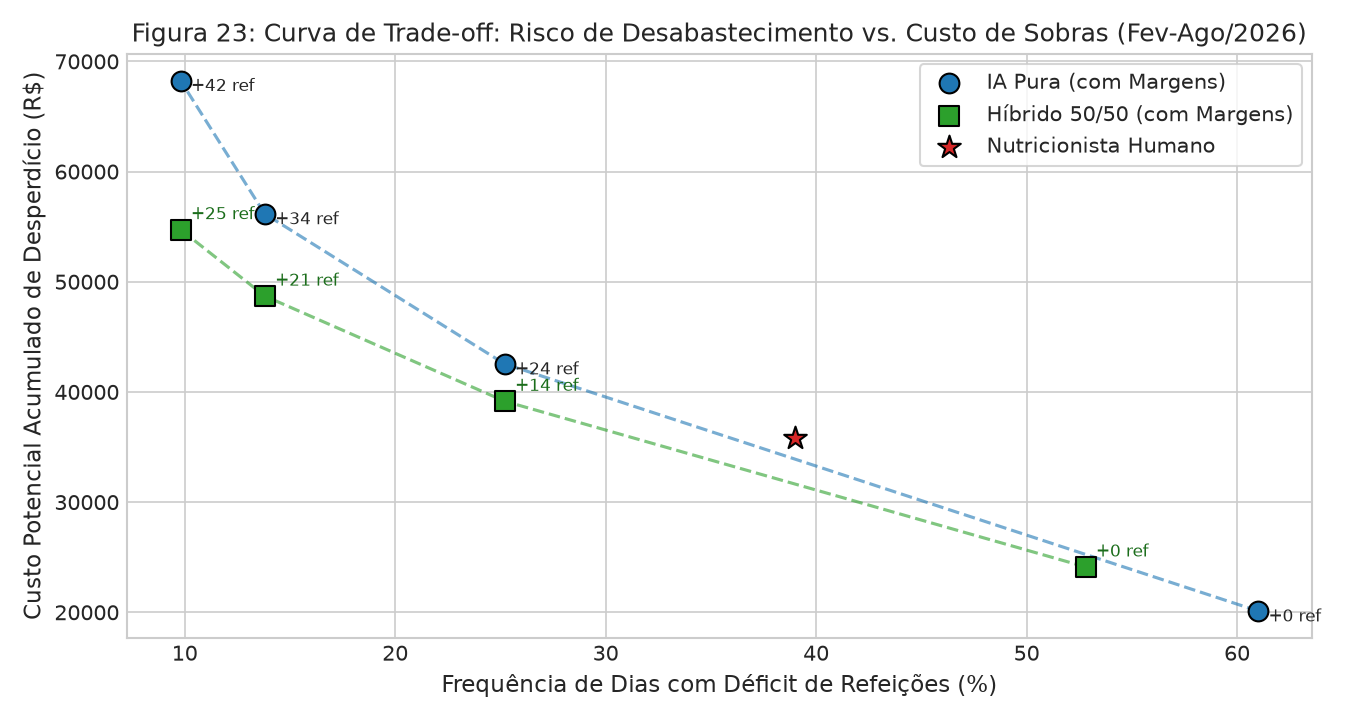

In [11]:
tabela_05 = pd.read_csv(PASTA_TABELAS / "tabela_05_politicas_margens_retrospectivo.csv", sep=";")
print("=== TABELA 05: AVALIAÇÃO DE POLÍTICAS E MARGENS EMPÍRICAS (FEV-AGO/2026) ===")
display(tabela_05[["Politica", "Quantil", "Margem", "MAE", "Sobra_Total_ref", "Deficit_Total_ref", "Dias_com_Deficit", "Taxa_Deficit_pct", "Custo_Potencial_Sobras_RS"]])
display(Image(filename=str(PASTA_FIGURAS / "figura_22_margens_seguranca_conformal_retrospectivo.png")))
display(Image(filename=str(PASTA_FIGURAS / "figura_23_tradeoff_sobras_deficits_custo_retrospectivo.png")))


## Conclusões da Avaliação Retrospectiva

1. **Seleção:** o melhor modelo no melhor cenário foi escolhido por horizonte, com o menor MAE em Fev-Ago. O resultado está em `resultados/modelos/selecao_modelos.json`, e só depois os modelos são congelados.
2. **Quantitativo institucional:** ao entrar como atributo, reduziu o erro dos modelos, sobretudo os lineares. O Modelo Híbrido 50/50 usa esse dado na combinação final.
3. **Horizonte de compras ($T+2$):** usa somente informação disponível na emissão, sem quantitativo institucional. Só uma parte pequena do treino tem previsão de clima arquivada, o que limita o Cenário 3 nesse horizonte.
4. **Treino e teste:** os modelos aprendem com dados anteriores a cada emissão. Fevereiro a agosto é o período avaliado, não todo o treino.
5. **Próximo passo:** o notebook 05 avalia o período prospectivo com o modelo congelado.
